In [1]:
from rdkit import Chem
import csv

In [2]:
success_indices = []
failed_indices = []
reaction_types = {}
terminated = False
with open(filename, 'r') as f:
    for line in f:
        if "Processing row" in line:
            rxn_idx = int(line.strip().split()[-1])
            found_line = True
        if found_line:
            if "Reaction type:" in line:
                rxn_type = line.strip().split(":")[-1].strip()
                if rxn_type not in reaction_types:
                    reaction_types[rxn_type] = [1,0]
                else:
                    reaction_types[rxn_type][0] += 1
            if "Terminating safely" in line:
                terminated = True
                continue
            if terminated:
                if "No products found, not saving tree" in line:
                    failed_indices.append(rxn_idx)
                else:
                    print(f"Reaction {rxn_idx}")
                    success_indices.append(rxn_idx)
                    reaction_types[rxn_type][1] += 1
                found_line = False
                terminated = False

            

NameError: name 'filename' is not defined

In [3]:
from pathlib import Path

def process_reaction_files(filenames):
    success_indices = []
    failed_indices = []
    reaction_types = {}
    
    unique_mechs = 0
    test_set_mechs = 0

    for filename in filenames:
        terminated = False
        found_line = False
        with open(filename, 'r') as f:
            for line in f:
                
                if found_line:
                    if terminated:
                        if "No products found, not saving tree" in line:
                            failed_indices.append(rxn_idx)
                        else:
                            print(f"Reaction {rxn_idx}")
                            success_indices.append(rxn_idx)
                            reaction_types[rxn_type][1] += 1
                        found_line = False
                    if "Reaction type:" in line:
                        rxn_type = line.strip().split(":")[-1].strip()
                        if rxn_type not in reaction_types:
                            reaction_types[rxn_type] = [1,0]
                        else:
                            reaction_types[rxn_type][0] += 1
                    if "Terminating safely" in line:
                        terminated = True
                        continue
                    
                if "Unique mechanisms found:" in line:
                    unique_mechs += int(line.strip().split()[-1])
                if "Test set mechanisms found:" in line:
                    test_set_mechs += int(line.strip().split()[-1])

                if "Processing row" in line:
                    rxn_idx = int(line.strip().split()[-1])
                    found_line = True
                    terminated = False
    
    return success_indices, failed_indices, reaction_types, unique_mechs, test_set_mechs

# Usage
# filenames = ['slurm-13974.out', 'slurm-13978.out', 'slurm-13979.out', 'slurm-13980.out', 'slurm-13981.out', 'slurm-13984.out', 'slurm-13985.out', 'slurm-13986.out', 'slurm-13987.out']  # Add your filenames here
filenums = [24911, 24912, 24913, 24914, 24915]

filenames = [f"slurm_out/slurm-{num}.out" for num in filenums]

# filenames = sorted([str(p) for p in Path('slurm_out').glob('*.out') if p.is_file()])
success_indices, failed_indices, reaction_types, unique_mechs, test_set_mechs = process_reaction_files(filenames)



Reaction 268
Reaction 378
Reaction 496
Reaction 1778
Reaction 2166
Reaction 4063
Reaction 4201
Reaction 4267
Reaction 6329
Reaction 8055
Reaction 9233
Reaction 10153
Reaction 10362
Reaction 10514
Reaction 10765
Reaction 11885
Reaction 12524
Reaction 16126
Reaction 20061
Reaction 23538
Reaction 24372
Reaction 667
Reaction 2576
Reaction 5370
Reaction 6362
Reaction 6734
Reaction 7802
Reaction 9940
Reaction 13316
Reaction 14746
Reaction 19201
Reaction 22177
Reaction 23003
Reaction 24815
Reaction 25935
Reaction 27937
Reaction 28385
Reaction 29671
Reaction 30518
Reaction 485
Reaction 2066
Reaction 2633
Reaction 5930
Reaction 8228
Reaction 9792
Reaction 10470
Reaction 12243
Reaction 12747
Reaction 12941
Reaction 15652
Reaction 16207
Reaction 16838
Reaction 22947
Reaction 23621
Reaction 23848
Reaction 24609
Reaction 25192
Reaction 26628
Reaction 27567
Reaction 28917
Reaction 783
Reaction 2905
Reaction 5434
Reaction 6845
Reaction 7328
Reaction 7565
Reaction 8365
Reaction 9030
Reaction 10936
Rea

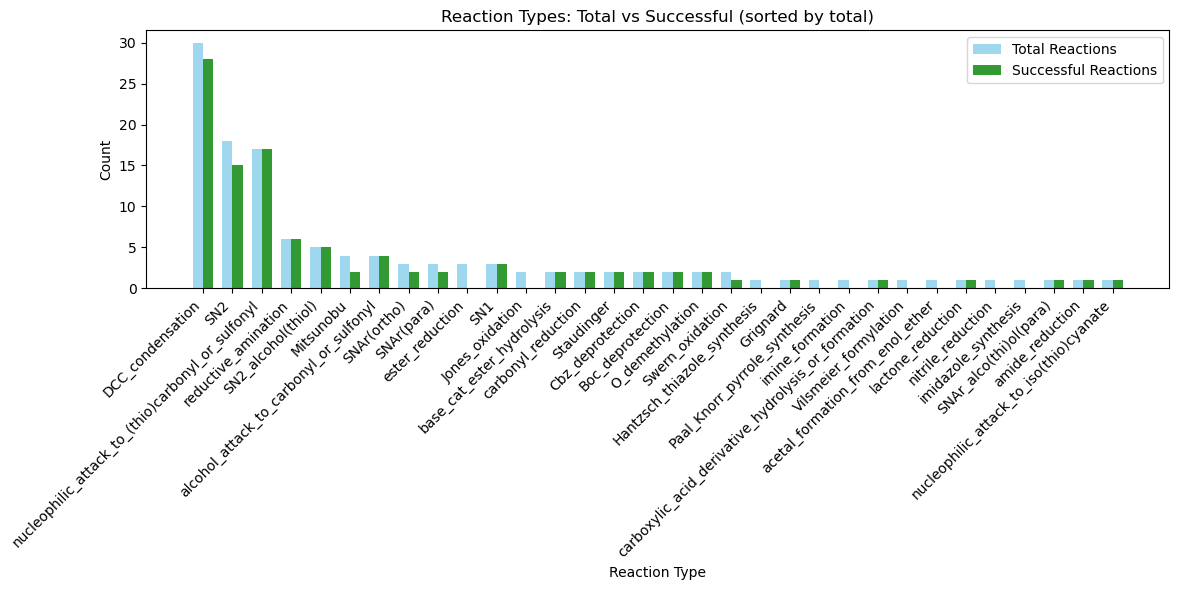

<Figure size 640x480 with 0 Axes>

In [4]:
import matplotlib.pyplot as plt

# Extract and sort by total descending
categories = list(reaction_types.keys())
total = [reaction_types[cat][0] for cat in categories]
successful = [reaction_types[cat][1] for cat in categories]

pairs = sorted(zip(categories, total, successful), key=lambda t: t[1], reverse=True)
if pairs:
    categories_sorted, total_sorted, successful_sorted = zip(*pairs)
else:
    categories_sorted, total_sorted, successful_sorted = [], [], []

# Create bar chart
fig, ax = plt.subplots(figsize=(12, 6))
x = range(len(categories_sorted))
width = 0.35

bars1 = ax.bar([i - width/2 for i in x], total_sorted, width, label='Total Reactions', color='skyblue', alpha=0.8)
bars2 = ax.bar([i + width/2 for i in x], successful_sorted, width, label='Successful Reactions', color='green', alpha=0.8)

ax.set_xlabel('Reaction Type')
ax.set_ylabel('Count')
ax.set_title('Reaction Types: Total vs Successful (sorted by total)')
ax.set_xticks(x)
ax.set_xticklabels(categories_sorted, rotation=45, ha='right')
ax.legend()
plt.tight_layout()
plt.show()
plt.savefig('plots/reaction_types_comparison_sorted.png', dpi=600)

In [5]:
print("Successful reaction indices:", success_indices)
print("Failed reaction indices:", failed_indices)
print("Percentage success", len(success_indices)/(len(success_indices)+len(failed_indices))*100)
print("Unique mechanisms found:", unique_mechs)
print("Test set mechanisms found:", test_set_mechs)
print("Percentage of recall from training data:", test_set_mechs/(unique_mechs+test_set_mechs)*100)

Successful reaction indices: [268, 378, 496, 1778, 2166, 4063, 4201, 4267, 6329, 8055, 9233, 10153, 10362, 10514, 10765, 11885, 12524, 16126, 20061, 23538, 24372, 667, 2576, 5370, 6362, 6734, 7802, 9940, 13316, 14746, 19201, 22177, 23003, 24815, 25935, 27937, 28385, 29671, 30518, 485, 2066, 2633, 5930, 8228, 9792, 10470, 12243, 12747, 12941, 15652, 16207, 16838, 22947, 23621, 23848, 24609, 25192, 26628, 27567, 28917, 783, 2905, 5434, 6845, 7328, 7565, 8365, 9030, 10936, 12458, 13705, 15083, 15361, 15779, 21116, 21763, 22276, 22347, 22630, 25209, 25452, 25869, 25882, 1780, 3182, 5500, 6688, 9180, 10719, 10801, 10814, 11618, 15654, 16206, 17992, 18053, 18823, 21605, 22235, 24988, 25040, 25313, 27404]
Failed reaction indices: [1494, 2911, 7258, 29969, 6504, 10309, 10602, 13514, 16703, 22646, 26326, 4139, 5398, 14477, 16767, 16855, 7799, 8864, 9080, 15309, 17732]
Percentage success 83.06451612903226
Unique mechanisms found: 2140906
Test set mechanisms found: 77893
Percentage of recall from

In [32]:
with open('reaction_subset.csv', 'r') as f:
    reader = csv.reader(f)
    rows = list(reader)

for idx in failed_indices[:9]:
    print(idx)
    rxn = rows[idx][0].split('>>')
    sm = Chem.MolFromSmiles(rxn[0])
    prod = Chem.MolFromSmiles(rxn[1])
    for atom in sm.GetAtoms():
        atom.SetAtomMapNum(0)
    for atom in prod.GetAtoms():
        atom.SetAtomMapNum(0)

print(Chem.MolToSmiles(sm))   
Chem.Draw.MolToImage(sm)
    

12141


IndexError: list index out of range

In [33]:


# Extract reaction type and get all failed indices for that type
rxn_type_current = rows[idx-1][2]
print(f"\nReaction type: {rxn_type_current}")

# Get all failed indices for each reaction type
for rxn_type_key in reaction_types.keys():
    failed_indices_by_type = []
    row = 0
    with open("mech-USPTO-31k.csv", 'r') as f:
        reader = csv.reader(f)
        for l in reader:
            row += 1
            if row in failed_indices and l[2] == rxn_type_key:
                failed_indices_by_type.append(row)
    
    print(f"Failed indices for {rxn_type_key}: {failed_indices_by_type}")
    

IndexError: list index out of range

In [6]:
from IPython.display import display
from ipywidgets import Button, Output, VBox, HBox, Dropdown, HTML
import pandas as pd
import csv
from rdkit import Chem

# Load the CSV file
with open("mech-USPTO-31k.csv", 'r') as f:
    reader = csv.reader(f)
    rows = list(reader)

# Create interactive viewer
current_idx = {'value': 0}
failed_to_show = failed_indices.copy()

reasons = {}

output_display = Output()
reason_input = Dropdown(
    options=[('Select reason...', ''), ('not possible', 'not possible'), ('fixed', 'fixed'),
            ('need more steps', 'need more steps'), ('stereochemistry', 'stereochemistry'),
            ('stoichiometry', 'stoichiometry'), ('retrain', 'retrain'), ('filtered', 'filtered'), ('other', 'other')],
    value=''
)

def show_reaction(idx):
    with output_display:
        output_display.clear_output()
        if idx >= len(failed_to_show):
            print("No more reactions to review")
            return

        row_num = failed_to_show[idx] - 1
        rxn = rows[row_num][1].split('>>')
        sm = Chem.MolFromSmiles(rxn[0])
        prod = Chem.MolFromSmiles(rxn[1])

        for atom in sm.GetAtoms():
            atom.SetAtomMapNum(0)
        for atom in prod.GetAtoms():
            atom.SetAtomMapNum(0)

        print(f"Reaction {idx + 1}/{len(failed_to_show)} - Row: {row_num + 1}")
        print(f"Type: {rows[row_num][2]}")
        print(f"SMILES: {Chem.MolToSmiles(sm)} >> {Chem.MolToSmiles(prod)}")
        display(Chem.Draw.MolToImage(sm))
        display(Chem.Draw.MolToImage(prod))

def on_next(b):
    current_idx['value'] += 1
    reason_input.value = ''
    show_reaction(current_idx['value'])

def on_prev(b):
    current_idx['value'] = max(0, current_idx['value'] - 1)
    reason_input.value = ''
    show_reaction(current_idx['value'])

def on_save(b):
    if current_idx['value'] < len(failed_to_show) and reason_input.value:
        reasons[failed_to_show[current_idx['value']]] = reason_input.value
        print(f"Saved reason: {reason_input.value}")

prev_btn = Button(description='Previous')
next_btn = Button(description='Next')
save_btn = Button(description='Save Reason')

prev_btn.on_click(on_prev)
next_btn.on_click(on_next)
save_btn.on_click(on_save)

show_reaction(0)
display(VBox([output_display, reason_input, HBox([prev_btn, save_btn, next_btn])]))

In [ ]:
# reorganise reasons -> rows
reason_to_rows = {}
for row, reason in reasons.items():
    reason_to_rows.setdefault(reason, []).append(row)

# sort rows for each reason
for k in reason_to_rows:
    reason_to_rows[k].sort()

print(reason_to_rows)



{'not possible': [6768, 7853, 11676, 21203, 23341, 24842, 26230], 'retrain': [1878, 4895, 4897, 5007, 8787, 10610, 10793, 11246, 11524, 12141, 20811, 21324, 23618, 25375, 29946], 'fixed': [2867, 10920, 16977, 24369, 28512], 'need more steps': [495, 837, 2442, 2779, 4057, 4918, 5777, 6864, 8572, 8932, 9037, 10096, 13512, 20516, 26179], 'filtered': [1835, 4937, 8373, 8791, 18754], 'stoichiometry': [7924, 16336, 18459, 23631, 24608, 24824, 26081], 'other': [30002, 30688], 'stereochemistry': [17345, 19615, 26998]}


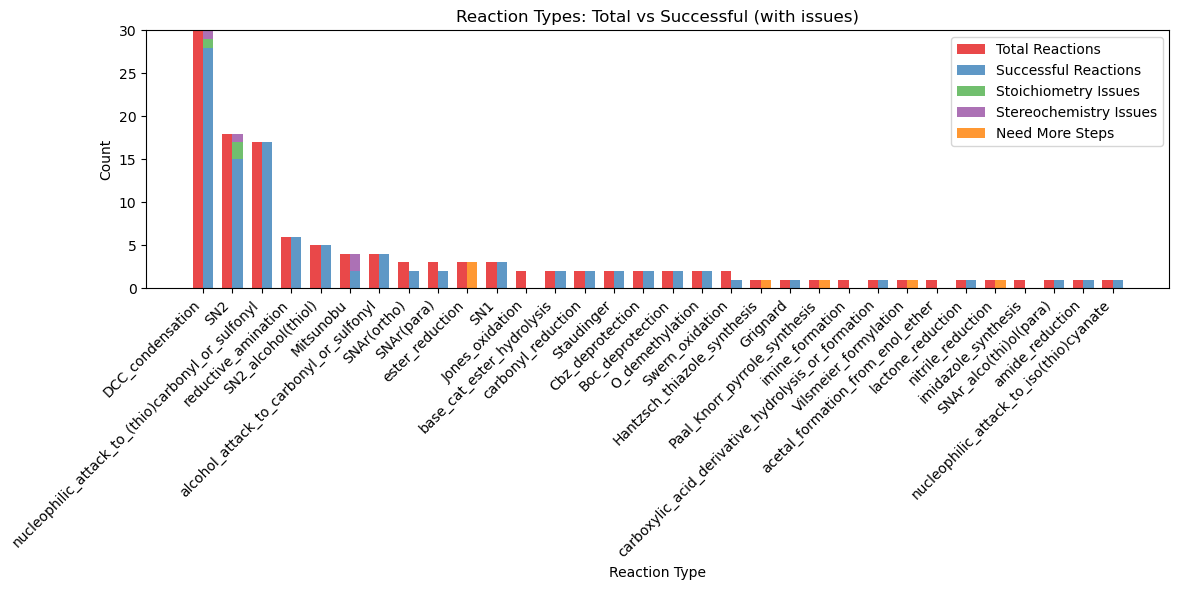

<Figure size 640x480 with 0 Axes>

In [11]:
# Count issues for each reaction type
stoich_issues = {k: 0 for k in reaction_types}
stereo_issues = {k: 0 for k in reaction_types}
more_steps_issues = {k: 0 for k in reaction_types}

for row, reason in reasons.items():
    rxn_type = rows[row-1][2]
    if reason == 'stoichiometry':
        stoich_issues[rxn_type] += 1
    elif reason == 'stereochemistry':
        stereo_issues[rxn_type] += 1
    elif reason == 'need more steps':
        more_steps_issues[rxn_type] += 1

# Prepare sorted values
stoich_sorted = [stoich_issues.get(cat, 0) for cat in categories_sorted]
stereo_sorted = [stereo_issues.get(cat, 0) for cat in categories_sorted]
more_steps_sorted = [more_steps_issues.get(cat, 0) for cat in categories_sorted]

fig, ax = plt.subplots(figsize=(12, 6))
x = range(len(categories_sorted))
width = 0.35

bars1 = ax.bar([i - width/2 for i in x], total_sorted, width, label='Total Reactions', color=plt.cm.Set1(0), alpha=0.8)
bars2 = ax.bar([i + width/2 for i in x], successful_sorted, width, label='Successful Reactions', color=plt.cm.Set1(1), alpha=0.8)
bars3 = ax.bar([i + width/2 for i in x], stoich_sorted, width, label='Stoichiometry Issues', color=plt.cm.Set1(2), alpha=0.8, bottom=successful_sorted)
bars4 = ax.bar([i + width/2 for i in x], stereo_sorted, width, label='Stereochemistry Issues', color=plt.cm.Set1(3), alpha=0.8, bottom=[successful_sorted[j]+stoich_sorted[j] for j in range(len(successful_sorted))])
bars5 = ax.bar([i + width/2 for i in x], more_steps_sorted, width, label='Need More Steps', color=plt.cm.Set1(4), alpha=0.8, bottom=[successful_sorted[j]+stoich_sorted[j]+stereo_sorted[j] for j in range(len(successful_sorted))])

ax.set_xlabel('Reaction Type')
ax.set_ylabel('Count')
ax.set_title('Reaction Types: Total vs Successful (with issues)')
ax.set_xticks(x)
ax.set_xticklabels(categories_sorted, rotation=45, ha='right')
ax.legend()
plt.tight_layout()
plt.show()
plt.savefig('plots/reaction_types_comparison_with_issues.png', dpi=600)

['O=[C:1]([c:2]1[cH:3][cH:4][cH:5][c:6]([CH2:7][O:8][C:9]([CH3:10])=[O:11])[n:12]1)[NH2:13]>>[C:1]([c:2]1[cH:3][cH:4][cH:5][c:6]([CH2:7][O:8][C:9]([CH3:10])=[O:11])[n:12]1)#[N:13]',
 '[O:101]=[C:1]([c:2]1[cH:3][cH:4][cH:5][c:6]([CH2:7][O:8][C:9]([CH3:10])=[O:11])[n:12]1)[NH2:13].[Cl:301][S:302]([Cl:303])=[O:304]>>[C:1]([c:2]1[cH:3][cH:4][cH:5][c:6]([CH2:7][O:8][C:9]([CH3:10])=[O:11])[n:12]1)#[N:13]',
 'primary_amide_dehydration',
 '[(13, [13, 1]), ([1, 101], 302), ([302, 304], 304), (304, [304, 302]), ([302, 301], 13.1), ([13.1, 13], 13), ([302, 303], 13.1), ([13.1, 13], [13, 1]), ([1, 101], [101, 302])]',
 'https://figshare.com/articles/dataset/Chemical_reactions_from_US_patents_1976-Sep2016_/5104873']

In [12]:
from ipywidgets import Output, Button, VBox, HBox, Checkbox, HTML
from IPython.display import display, HTML as DispHTML
import re
import os
import pickle
from rdkit.Chem import Draw

def _visualise_tree(node):
    mols = [Chem.MolFromSmiles(node.smiles)]
    while not node.is_root:
        node = node.parent
        mols.append(Chem.MolFromSmiles(node.smiles))
    mols.reverse()
    return Draw.MolsToGridImage(
        mols,
        molsPerRow=3,
        subImgSize=(400, 400),
        legends=[f"Mol {i}" for i in range(len(mols))],
    )


def _get_node_from_slurm(slurm_id):
    node = None
    for path in [
        f"old_slurm/slurm-{slurm_id}.out",
        f"slurm_out/slurm-{slurm_id}.out",
        f"slurm-{slurm_id}.out",
    ]:
        try:
            with open(path, "r") as f:
                lines = f.readlines()
            for line in lines:
                if "Running on master node:" in line:
                    node = line.split(":")[-1].split(".")[0].strip()
                    return node
        except Exception:
            continue
    return None


def _load_and_visualize_tree(slurm_id, node_dir_root="/nodescratch", row_id=None):
    node = _get_node_from_slurm(slurm_id)
    if node is None:
        raise RuntimeError(f"Could not find slurm output for {slurm_id}")

    node_dir = os.path.join(node_dir_root, node, "rd611", str(slurm_id))
    if not os.path.isdir(node_dir):
        raise RuntimeError(f"Node directory not found: {node_dir}")

    files = os.listdir(node_dir)
    if len(files) == 1:
        filename = files[0]
        pickle_path = os.path.join(node_dir, filename)
        with open(pickle_path, "rb") as file:
            node = pickle.load(file)
        image = _visualise_tree(node)
        return [image]

    out_images = []
    for filename in files:
        if filename.startswith(str(slurm_id)) and filename.endswith(".pkl"):
            parts = filename.split(".")[0].split("_")[1:]
            suffix = "_".join(parts) if parts else ""
            if suffix.split("_")[0] == str(row_id):
                pickle_path = os.path.join(node_dir, filename)
                with open(pickle_path, "rb") as file:
                    node = pickle.load(file)
                image = _visualise_tree(node)
                out_images.append((suffix, image))
    return out_images


def _find_slurm_for_row(row_id, search_dirs, pattern):
    row_id_str = str(row_id)
    row_re = re.compile(pattern.format(row_id=re.escape(row_id_str)))
    for d in search_dirs:
        if not os.path.isdir(d):
            continue
        for name in os.listdir(d):
            if not name.endswith(".out"):
                continue
            path = os.path.join(d, name)
            try:
                with open(path, "r", errors="ignore") as f:
                    text = f.read()
                if row_re.search(text):
                    # slurm-XXXXX.out
                    base = os.path.basename(name)
                    try:
                        slurm_id = int(base.split("-")[1].split(".")[0])
                        return slurm_id
                    except Exception:
                        continue
            except Exception:
                continue
    return None


def make_success_viewer_by_row(
    row_ids,
    search_dirs=None,
    row_pattern=r"\\b{row_id}\\b",
    node_dir_root="/nodescratch",
):
    """
    row_pattern is a regex template containing {row_id}. Default matches the
    row number as a standalone token. If your logs contain "Row: <id>",
    consider row_pattern=r"Row:\\s*{row_id}\\b".
    """

    if search_dirs is None:
        search_dirs = ["slurm_out", "old_slurm", "."]

    current_idx = {"value": 0}
    current_row = {"value": None}
    output_display = Output()
    status = HTML()
    ratings = {}  # row_id -> bool
    ignore_chk = {"value": False}

    good_chk = Checkbox(description="Good", value=False)

    def show_success(idx):
        with output_display:
            output_display.clear_output()
            if idx >= len(row_ids):
                print("No more reactions to review")
                return

            row_id = row_ids[idx]
            current_idx["value"] = idx
            current_row["value"] = row_id

            status.value = f"<b>Success {idx + 1}/{len(row_ids)}</b> (Row {row_id})"
            slurm_id = _find_slurm_for_row(row_id, search_dirs, row_pattern)
            if slurm_id is None:
                print(f"No slurm output found containing row {row_id}")
                # update checkbox to saved value or default
                ignore_chk["value"] = True
                good_chk.value = ratings.get(row_id, False)
                ignore_chk["value"] = False
                return

            try:
                images = _load_and_visualize_tree(
                    slurm_id, node_dir_root=node_dir_root, row_id=row_id
                )
            except Exception as e:
                print(f"Failed to visualize row {row_id} (slurm {slurm_id}): {e}")
                ignore_chk["value"] = True
                good_chk.value = ratings.get(row_id, False)
                ignore_chk["value"] = False
                return

            # set checkbox to saved value (without triggering save)
            ignore_chk["value"] = True
            good_chk.value = ratings.get(row_id, False)
            ignore_chk["value"] = False

            # images can be list[Image] (single) or list[(suffix, Image)] (multi)
            if images and isinstance(images[0], tuple):
                for suffix, image in images:
                    label = f"SLURM {slurm_id} — {suffix}" if suffix else f"SLURM {slurm_id}"
                    display(DispHTML(f"<div>{label}</div>"))
                    display(image)
            else:
                for image in images:
                    display(DispHTML(f"<div>SLURM {slurm_id}</div>"))
                    display(image)

    def on_next(_):
        current_idx["value"] += 1
        show_success(current_idx["value"])

    def on_prev(_):
        current_idx["value"] = max(0, current_idx["value"] - 1)
        show_success(current_idx["value"])

    def on_chk_change(change):
        if ignore_chk["value"]:
            return
        row = current_row["value"]
        if row is not None:
            ratings[row] = bool(change["new"])

    prev_btn = Button(description="Previous")
    next_btn = Button(description="Next")
    prev_btn.on_click(on_prev)
    next_btn.on_click(on_next)
    good_chk.observe(on_chk_change, names="value")

    show_success(0)
    viewer = VBox([status, output_display, HBox([prev_btn, good_chk, next_btn])])
    viewer.ratings = ratings  # attach dict so caller can access saved ratings
    return viewer


__all__ = ["make_success_viewer_by_row"]


In [13]:
viewer = make_success_viewer_by_row(
    success_indices, search_dirs=["slurm_out"], row_pattern=r"Processing row\s*{row_id}\b",   # adjust if your logs differ
      node_dir_root="/nodescratch"
  )

display(viewer)


In [39]:
with open('mech-USPTO-31k.csv', 'r') as f:
    reader = csv.reader(f)
    rows = list(reader)
# for row in set(success_indices[:50])-set(viewer.ratings.keys()):
for row in [1878, 4895, 4897, 5007, 8787, 10610, 10793, 11246, 11524, 12141, 20811, 21324, 23618, 25375, 29946]:
    m = Chem.MolFromSmiles(rows[row-1][1].split('>>')[0])
    for a in m.GetAtoms():
        a.SetAtomMapNum(0)
    print(Chem.MolToSmiles(m))

CC(=O)OCc1cccc(C(N)=O)n1.O=S(Cl)Cl
CC(C)(C)OC(=O)Nc1cc(F)c(F)cc1Br.CI
CC(Br)C(=O)N1CCCC1.COC(=O)c1c(C)[nH]c2ccccc12
CI.c1ccc2oc(-c3ncc[nH]3)cc2c1
CCC1CC(CCCC(N)=O)CC1c1nnc2cnc3[nH]ccc3n12.O=S(Cl)Cl
COc1cc2c(cc1OC)C1CC(=O)C3CCCCC3N1CC2.O.[Mg+][c]1ccccc1
CC(C)(C)c1nc(-c2cccc(N)c2F)c(-c2ccnc(N)n2)s1.O=S(=O)(Cl)c1ccccc1
CCOC(=O)C(C)Br.Oc1ccc(C2CCCCC2)cc1
CC(C)(C)OC(=O)N1CCc2ccc(N)cc2CC1.O=S(=O)(Cl)c1ccccc1
NC(=O)c1cc2ccccc2[nH]1.O=S(Cl)Cl
O=C(O)C=CC(=O)c1ccccc1O.[Na+].[OH-]
CCOC(=O)c1cc2ccc(C)c(N)c2[nH]1.O=S(=O)(Cl)c1cccs1
CI.COc1cnc(-c2cc[nH]n2)c2[nH]cc(C(=O)C(=O)N3CCN(c4nnnn4-c4ccccn4)CC3)c12
CI.O=Cc1cccc2[nH]ccc12
C=CC(=O)OCCCC.CC(C)(C)c1ccc(O)cc1.[Na+].[OH-]


In [17]:
len(set(success_indices)-set(viewer.ratings.keys()))

49

In [8]:
for k,v in reasons.items():
    if v == 'need more steps':
        print(k)

13512
8572
10096
495
20516
2442
837


as a general rule  
Carbonyl reduction - stereochemistry  
Nitrile reduction - need more steps  
Ester reduction - need more steps  
Wittig - not possible  
Horner-Wadsworth-Emmons -not possible  
Appel - not possible  
Ing-Maske - need more steps

In [51]:
import pandas as pd

# Create a dataframe from the reasons dictionary
results_df = pd.DataFrame(list(reasons.items()), columns=['Row_Index', 'Reason'])

# Save to CSV
results_df.to_csv('failure_reasons_2.csv', index=False)

print(f"Saved {len(results_df)} results to 'failure_reasons.csv'")

Saved 16 results to 'failure_reasons.csv'


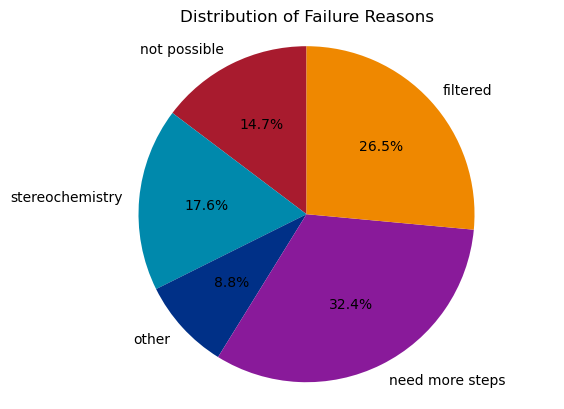

In [11]:
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt

custom_colors = [
    (169, 27, 46),  # blue-ish
    (0, 138, 173),  # red-ish
    (0, 48, 136),  # green-ish
    (138, 26, 155),  # yellow-ish
    (240, 137, 0)   # purple-ish
]

custom_c = [ tuple(c[i] / 256.0 for i in range(3)) for c in custom_colors ]

custom_cmap = ListedColormap(custom_c)

# Count the reasons
reason_counts = {}
for reason in reasons.values():
    reason_counts[reason] = reason_counts.get(reason, 0) + 1

# Create pie chart
labels = list(reason_counts.keys())
sizes = list(reason_counts.values())
fig, ax = plt.subplots()
ax.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=custom_c)
ax.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.title('Distribution of Failure Reasons')
plt.show()

In [10]:
# Calculate true failures: only "not possible" and "filtered"
true_failures = sum(1 for reason in reasons.values() if reason in ["not possible", "filtered"])

# Total reactions
total_reactions = len(success_indices) + len(failed_indices)

# New failure rate
new_failure_rate = (true_failures / total_reactions) * 100 if total_reactions > 0 else 0

print(f"New success rate (only 'not possible' and 'filtered' as failures): {100 - new_failure_rate:.2f}%")

New success rate (only 'not possible' and 'filtered' as failures): 91.91%


In [ ]:
# Show all reactions labeled "other" or "filtered"
matches = [r for r, reason in reasons.items() if reason in ("other", "filtered")]

if not matches:
    print("No reactions labeled 'other' or 'filtered'.")
else:
    for row in sorted(matches):
        row_idx = row - 1
        rxn_line = rows[row_idx][1]
        parts = rxn_line.split(">>")
        react_smiles = parts[0].strip()
        prod_smiles = parts[1].strip() if len(parts) > 1 else ""
        sm = Chem.MolFromSmiles(react_smiles)
        prod = Chem.MolFromSmiles(prod_smiles) if prod_smiles else None
        if sm:
            for a in sm.GetAtoms():
                a.SetAtomMapNum(0)
        if prod:
            for a in prod.GetAtoms():
                a.SetAtomMapNum(0)
        print(f"Row {row} | Type: {rows[row_idx][2]} | Reason: {reasons[row]}")
        print(f"SMILES: {react_smiles} >> {prod_smiles}")
        display(Chem.Draw.MolToImage(sm))
        if prod:
            display(Chem.Draw.MolToImage(prod))

In [ ]:
with open("mech-USPTO-31k.csv", 'r') as f:
    reader = csv.reader(f)
    row = 0
    for l in reader:
        row += 1
        if row not in failed_indices:
            continue
        print("_"*40)
        print(f"Processing row {row}")
        print(l[1])
        print(f"Reaction type: {l[2]}")
        line = l[1]
        l_s = line.split(">>")
        reactant = l_s[0].strip()
        product = l_s[1].strip()
        try:
            run_parallel(reactant, product, str(row))
        except Exception as e:
            print(e)